# Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io

In [2]:
df = pd.read_csv("smart_waste_generation.csv")

In [3]:
df.head()

,record_id,date,city,ward,waste_type,population,households,temperature_c,rainfall_mm,humidity_pct,commercial_activity_index,tourism_index,festival_flag,day_of_week,weekend_flag,waste_generated_tonnes_perday
0,19993,25-10-2022,Nashik,NAS-51,Plastic,7859.0,1804.0,24.6,NaN,41.5,97.0,82.0,1.0,Tuesday,0.0,1.835
1,2453,14-09-2022,Pune,PUN-58,Organic,9159.0,1953.0,26.7,1.6,55.7,99.0,50.0,0.0,Wednesday,0.0,2.946
2,24743,31-03-2023,Aurangabad,AUR-06,E-waste,15177.0,3596.0,29.6,0.0,44.0,53.0,82.0,0.0,Friday,0.0,0.310
3,13238,21-07-2023,Nashik,NAS-19,Glass,22155.0,4993.0,37.6,25.9,79.6,54.0,44.0,1.0,Friday,0.0,2.197
4,14340,05-04-2024,Nagpur,NAG-44,Plastic,17785.0,3891.0,32.3,1.7,53.6,15.0,49.0,0.0,Friday,0.0,2.395


In [4]:
df.shape

(51000, 16)

In [5]:
print(df.columns)

Index(['record_id', 'date', 'city', 'ward', 'waste_type', 'population',
       'households', 'temperature_c', 'rainfall_mm', 'humidity_pct',
       'commercial_activity_index', 'tourism_index', 'festival_flag',
       'day_of_week', 'weekend_flag', 'waste_generated_tonnes_perday'],
      dtype='object')


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51000 entries, 0 to 50999
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   record_id                      51000 non-null  int64  
 1   date                           51000 non-null  object 
 2   city                           49993 non-null  object 
 3   ward                           49514 non-null  object 
 4   waste_type                     50059 non-null  object 
 5   population                     48947 non-null  float64
 6   households                     48530 non-null  float64
 7   temperature_c                  48386 non-null  float64
 8   rainfall_mm                    47939 non-null  float64
 9   humidity_pct                   48462 non-null  float64
 10  commercial_activity_index      49431 non-null  float64
 11  tourism_index                  49502 non-null  float64
 12  festival_flag                  50055 non-null 

# Data Cleaning and Preprocessing

In [7]:
df.isnull().sum()

,0
record_id,0
date,0
city,1007
ward,1486
waste_type,941
population,2053
households,2470
temperature_c,2614
rainfall_mm,3061
humidity_pct,2538


In [8]:
df.duplicated().sum()

np.int64(1000)

In [9]:
df.describe()

,record_id,population,households,temperature_c,rainfall_mm,humidity_pct,commercial_activity_index,tourism_index,festival_flag,weekend_flag,waste_generated_tonnes_perday
count,51000.000000,48947.000000,48530.000000,48386.000000,47939.000000,48462.000000,49431.000000,49502.000000,50055.000000,49979.000000,50482.000000
mean,24990.817529,11543.377020,2635.056481,29.009740,6.002107,55.036526,50.459145,50.579108,0.087624,0.286280,2.608143
std,14441.927236,5552.356829,1191.595352,4.940575,9.130858,15.872045,28.815168,28.836829,0.282750,0.452026,2.006769
min,1.000000,800.000000,250.000000,13.700000,0.000000,20.000000,1.000000,1.000000,0.000000,0.000000,0.100000
25%,12478.750000,7375.000000,1707.000000,25.000000,0.500000,42.900000,26.000000,26.000000,0.000000,0.000000,1.123000
50%,24982.500000,10699.000000,2482.000000,29.000000,2.200000,50.900000,50.000000,51.000000,0.000000,0.000000,2.098000
75%,37505.250000,14847.000000,3445.000000,33.000000,7.400000,68.400000,75.000000,76.000000,0.000000,1.000000,3.566000
max,50000.000000,27000.000000,5000.000000,44.700000,94.100000,100.000000,100.000000,100.000000,1.000000,1.000000,17.637000


In [10]:
print(df.dtypes)

record_id                          int64
date                              object
city                              object
ward                              object
waste_type                        object
population                       float64
households                       float64
temperature_c                    float64
rainfall_mm                      float64
humidity_pct                     float64
commercial_activity_index        float64
tourism_index                    float64
festival_flag                    float64
day_of_week                       object
weekend_flag                     float64
waste_generated_tonnes_perday    float64
dtype: object


In [11]:
#convert data column
df["date"] = pd.to_datetime(df["date"])

/tmp/ipykernel_2730/3829339445.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["date"] = pd.to_datetime(df["date"])


In [12]:
df = df.drop_duplicates()

In [13]:
#handle missing values
for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype in ["int64", "float64"]:
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

Missing values after cleaning:
0


In [14]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

df.head()

Dataset shape: (50000, 16)
Missing values: 0
Duplicate rows: 0


,record_id,date,city,ward,waste_type,population,households,temperature_c,rainfall_mm,humidity_pct,commercial_activity_index,tourism_index,festival_flag,day_of_week,weekend_flag,waste_generated_tonnes_perday
0,19993,2022-10-25,Nashik,NAS-51,Plastic,7859.0,1804.0,24.6,2.2,41.5,97.0,82.0,1.0,Tuesday,0.0,1.835
1,2453,2022-09-14,Pune,PUN-58,Organic,9159.0,1953.0,26.7,1.6,55.7,99.0,50.0,0.0,Wednesday,0.0,2.946
2,24743,2023-03-31,Aurangabad,AUR-06,E-waste,15177.0,3596.0,29.6,0.0,44.0,53.0,82.0,0.0,Friday,0.0,0.310
3,13238,2023-07-21,Nashik,NAS-19,Glass,22155.0,4993.0,37.6,25.9,79.6,54.0,44.0,1.0,Friday,0.0,2.197
4,14340,2024-04-05,Nagpur,NAG-44,Plastic,17785.0,3891.0,32.3,1.7,53.6,15.0,49.0,0.0,Friday,0.0,2.395


In [15]:
df.describe()

,record_id,date,population,households,temperature_c,rainfall_mm,humidity_pct,commercial_activity_index,tourism_index,festival_flag,weekend_flag,waste_generated_tonnes_perday
count,50000.000000,50000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000
mean,25000.500000,2023-07-01 03:58:29.568000256,11512.534340,2628.549380,29.012194,5.775140,54.843642,50.42776,50.599240,0.086060,0.280680,2.604212
min,1.000000,2021-01-01 00:00:00,800.000000,250.000000,13.700000,0.000000,20.000000,1.00000,1.000000,0.000000,0.000000,0.100000
25%,12500.750000,2022-04-01 00:00:00,7508.750000,1746.000000,25.200000,0.600000,43.300000,26.00000,26.000000,0.000000,0.000000,1.130000
50%,25000.500000,2023-06-29 00:00:00,10701.000000,2483.000000,29.000000,2.200000,50.900000,50.00000,51.000000,0.000000,0.000000,2.098000
75%,37500.250000,2024-09-26 00:00:00,14636.000000,3385.000000,32.800000,6.800000,67.400000,75.00000,75.000000,0.000000,1.000000,3.545000
max,50000.000000,2025-12-31 00:00:00,27000.000000,5000.000000,44.700000,94.100000,100.000000,100.00000,100.000000,1.000000,1.000000,17.637000
std,14433.901067,NaN,5443.548499,1163.424485,4.812119,8.898435,15.499419,28.35842,28.405798,0.280455,0.449336,1.999452


# EDA

In [17]:
#Our target column is waste_generated_tonnes_perday, which we want to predict.
print(df["waste_generated_tonnes_perday"].describe())

count    50000.000000
mean         2.604212
std          1.999452
min          0.100000
25%          1.130000
50%          2.098000
75%          3.545000
max         17.637000
Name: waste_generated_tonnes_perday, dtype: float64


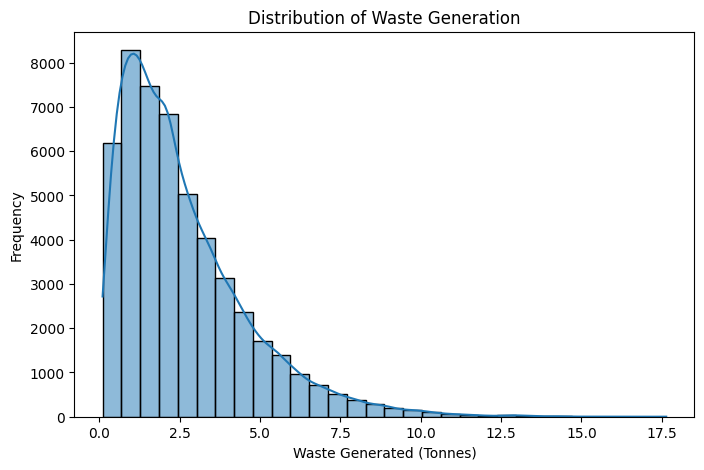

In [18]:
#Plot the waste generation distribution
#This graph shows how frequently different waste-generation amounts occur.
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df["waste_generated_tonnes_perday"], bins=30, kde=True)
plt.title("Distribution of Waste Generation")
plt.xlabel("Waste Generated (Tonnes)")
plt.ylabel("Frequency")
plt.show()

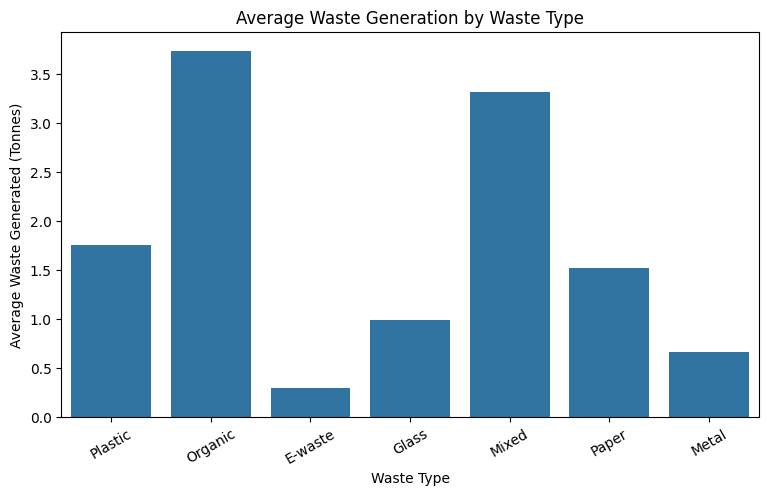

In [19]:
#Compare waste generation by waste type
plt.figure(figsize=(9, 5))
sns.barplot(data=df, x="waste_type", y="waste_generated_tonnes_perday", errorbar=None)
plt.title("Average Waste Generation by Waste Type")
plt.xlabel("Waste Type")
plt.ylabel("Average Waste Generated (Tonnes)")
plt.xticks(rotation=30)
plt.show()

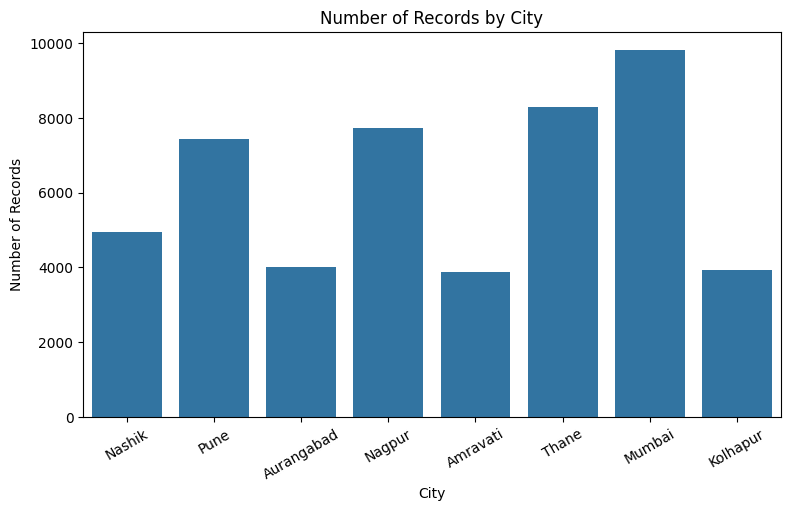

In [21]:
#Count records by city
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="city")
plt.title("Number of Records by City")
plt.xlabel("City")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.show()

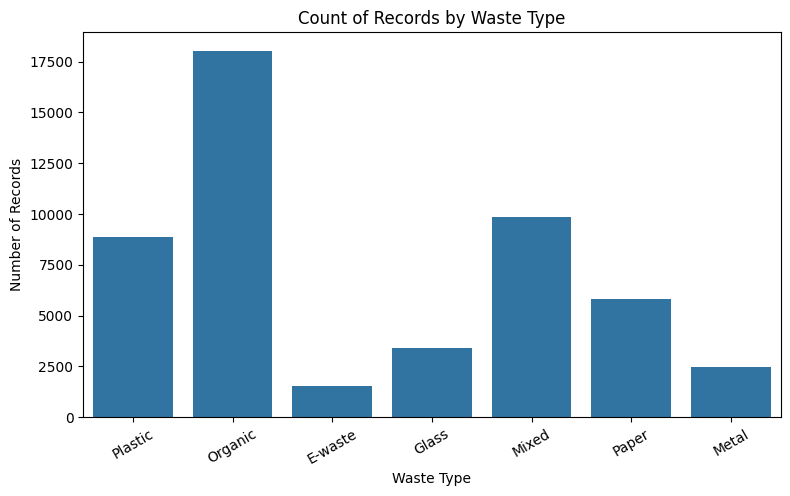

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

# Corrected to use the actual waste dataset column
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="waste_type")

plt.title("Count of Records by Waste Type")
plt.xlabel("Waste Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.show()

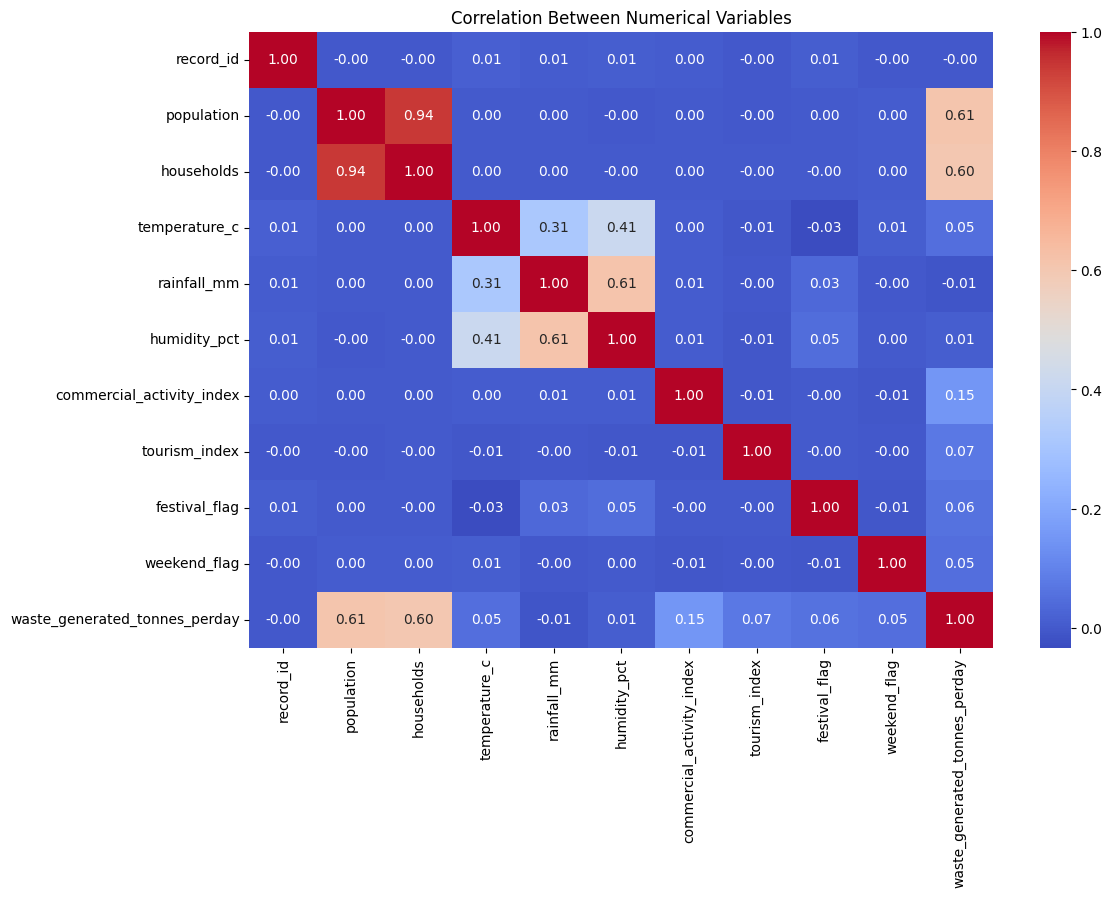

In [23]:
#Correlation heatmap
#This helps us understand relationships between numerical variables, such as population and waste generation.
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Variables")
plt.show()

In [24]:
#Average waste generation by city
city_waste = df.groupby("city")["waste_generated_tonnes_perday"].mean().sort_values(ascending=False)

print(city_waste)

city
Mumbai        3.075874
Pune          2.793393
Thane         2.606570
Nagpur        2.524049
Nashik        2.353521
Aurangabad    2.301997
Kolhapur      2.284677
Amravati      2.158044
Name: waste_generated_tonnes_perday, dtype: float64


# Descriptive Statistics

In [25]:
#Calculate minimum, maximum and range
print("Minimum:", df[col].min())
print("Maximum:", df[col].max())
print("Range:", df[col].max() - df[col].min())

Minimum: 0.1
Maximum: 17.637
Range: 17.537


In [26]:
#Calculate quartiles
print("25th Percentile (Q1):", df[col].quantile(0.25))
print("50th Percentile (Q2):", df[col].quantile(0.50))
print("75th Percentile (Q3):", df[col].quantile(0.75))

25th Percentile (Q1): 1.13
50th Percentile (Q2): 2.098
75th Percentile (Q3): 3.545


In [27]:
#Display all statistics together
df[col].describe()

,waste_generated_tonnes_perday
count,50000.000000
mean,2.604212
std,1.999452
min,0.100000
25%,1.130000
50%,2.098000
75%,3.545000
max,17.637000


# Probability Distribution

To understand how waste-generation values are distributed

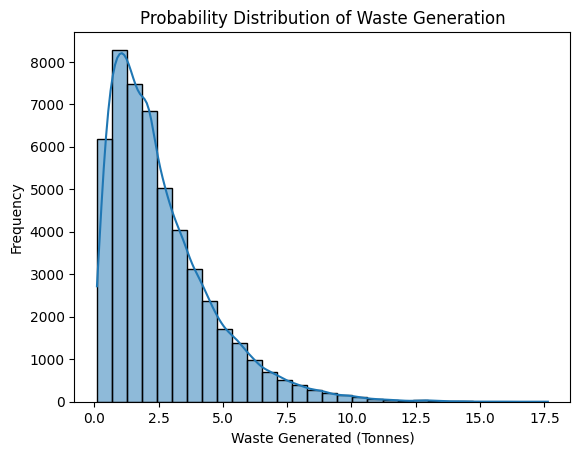

In [29]:
#Plot the distribution
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df["waste_generated_tonnes_perday"], bins=30, kde=True)
plt.title("Probability Distribution of Waste Generation")
plt.xlabel("Waste Generated (Tonnes)")
plt.ylabel("Frequency")
plt.show()

In [30]:
#Calculate skewness and kurtosis
col = "waste_generated_tonnes_perday"

print("Skewness:", df[col].skew())
print("Kurtosis:", df[col].kurt())

Skewness: 1.4741586328295522
Kurtosis: 2.8746202857901797


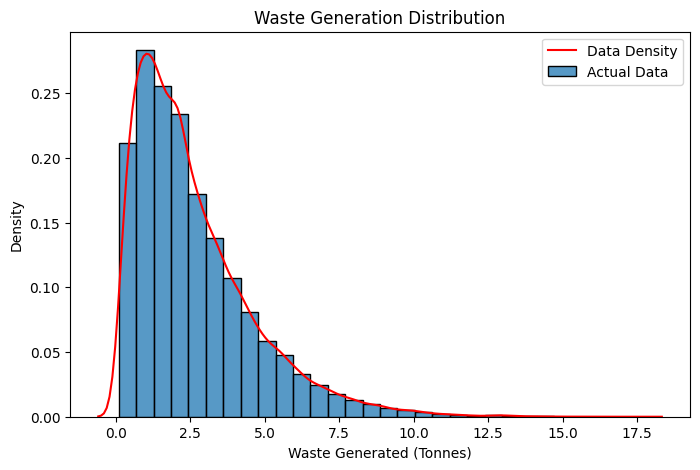

In [31]:
#Plot a normal distribution comparison
plt.figure(figsize=(8, 5))

sns.histplot(df[col], bins=30, stat="density", label="Actual Data")
sns.kdeplot(df[col], color="red", label="Data Density")

plt.title("Waste Generation Distribution")
plt.xlabel("Waste Generated (Tonnes)")
plt.legend()
plt.show()

# Sampling Techniques

To demonstrate different ways to select recoreds from dataset

In [32]:
#Simple Random Sampling
simple_sample = df.sample(n=500, random_state=42)

print(simple_sample.head())
print("Sample size:", len(simple_sample))

       record_id       date        city    ward waste_type  population  \
33988       6417 2023-08-21      Mumbai  NAG-11      Mixed     10701.0   
9453       38276 2022-01-18    Kolhapur  KOL-31    Plastic     18513.0   
199        25247 2025-08-19  Aurangabad  AUR-05    Organic     16675.0   
12498       7495 2024-11-29    Amravati  AMR-25    Plastic      5343.0   
40115       8930 2022-08-09      Nagpur  NAG-31      Paper     13339.0   

       households  temperature_c  rainfall_mm  humidity_pct  \
33988      3735.0           29.3         18.0          49.8   
9453       4425.0           19.1          1.5          36.7   
199        2483.0           32.4          8.4          81.8   
12498      1222.0           21.4          2.2          44.3   
40115      3018.0           29.7         18.1          87.7   

       commercial_activity_index  tourism_index  festival_flag day_of_week  \
33988                       22.0           81.0            0.0      Monday   
9453                

In [33]:
#Systematic Sampling
#Select every 10th record.
systematic_sample = df.iloc[::10]

print(systematic_sample.head())
print("Sample size:", len(systematic_sample))

    record_id       date      city    ward waste_type  population  households  \
0       19993 2022-10-25    Nashik  NAS-51    Plastic      7859.0      1804.0   
10       2310 2023-07-30  Amravati  AMR-27    Organic      8319.0      1872.0   
20      24104 2021-01-12    Nagpur  NAG-40      Paper     17631.0      3949.0   
30      25024 2024-03-31     Thane  THA-09    Plastic      4731.0      1207.0   
40      47509 2021-06-09     Thane  THA-53    Plastic     11127.0      2476.0   

    temperature_c  rainfall_mm  humidity_pct  commercial_activity_index  \
0            24.6          2.2          41.5                       97.0   
10           35.8          9.8          73.1                       90.0   
20           27.4          0.1          34.7                       14.0   
30           27.5          0.8          64.3                        1.0   
40           32.3         18.4          78.6                        2.0   

    tourism_index  festival_flag day_of_week  weekend_flag  \


In [34]:
#Stratified Sampling
#Select samples from each waste type so that each category is represented proportionally.
stratified_sample = (
    df.groupby("waste_type", group_keys=False)
      .sample(frac=0.2, random_state=42)
)

print(stratified_sample.head())
print(stratified_sample["waste_type"].value_counts())
print("Sample size:", len(stratified_sample))

       record_id       date        city    ward waste_type  population  \
1814        4400 2023-11-28  Aurangabad  AUR-18    E-waste     17377.0   
5509       37717 2024-12-13       Thane  MUM-05    E-waste     21677.0   
49473      12344 2021-08-28    Amravati  AMR-02    E-waste     13032.0   
30335      47987 2024-04-15      Nagpur  NAG-48    E-waste     18000.0   
13136       7723 2023-05-14      Mumbai  MUM-06    E-waste      5620.0   

       households  temperature_c  rainfall_mm  humidity_pct  \
1814       4141.0           25.7          7.6          39.4   
5509       5000.0           25.1          0.7          52.9   
49473      3223.0           29.8         11.1          76.6   
30335      4119.0           34.5          2.7          39.9   
13136      1282.0           36.2          0.8          44.6   

       commercial_activity_index  tourism_index  festival_flag day_of_week  \
1814                        34.0           98.0            0.0     Tuesday   
5509                

In [35]:
# Select 2 random locations (using 'city' column)
locations = df["city"].unique()
selected = pd.Series(locations).sample(n=2, random_state=42)

# Select all records from those locations
cluster_sample = df[df["city"].isin(selected)]

print(cluster_sample.head())
print("Cluster sample size:", len(cluster_sample))

   record_id       date   city    ward waste_type  population  households  \
1       2453 2022-09-14   Pune  PUN-58    Organic      9159.0      1953.0   
6      30456 2024-08-17  Thane  THA-44      Mixed     21886.0      4775.0   
7       6902 2021-08-18   Pune  PUN-48    E-waste     21769.0      4984.0   
8      38159 2025-03-06   Pune  PUN-07      Mixed     17571.0      4167.0   
9      15893 2021-02-16  Thane  THA-05      Mixed     13052.0      3187.0   

   temperature_c  rainfall_mm  humidity_pct  commercial_activity_index  \
1           26.7          1.6          55.7                       99.0   
6           32.1         30.0          84.2                       85.0   
7           28.0          2.2          65.5                       24.0   
8           29.0          2.2          45.8                       99.0   
9           29.6          2.1          36.7                       37.0   

   tourism_index  festival_flag day_of_week  weekend_flag  \
1           50.0            0.0

In [36]:
#Compare the sampling methods
print("Original dataset:", len(df))
print("Simple random sample:", len(simple_sample))
print("Systematic sample:", len(systematic_sample))
print("Stratified sample:", len(stratified_sample))
print("Cluster sample:", len(cluster_sample))

Original dataset: 50000
Simple random sample: 500
Systematic sample: 5000
Stratified sample: 10000
Cluster sample: 15726


# CLT

In [37]:
#Calculate the population mean
population_mean = df["waste_generated_tonnes_perday"].mean()

print("Population Mean:", population_mean)

Population Mean: 2.6042121799999998


In [39]:
#Take repeated samples and calculate their means
import numpy as np
import matplotlib.pyplot as plt

sample_means = []

for i in range(1000):
    sample = df["waste_generated_tonnes_perday"].sample(
        n=30, random_state=i
    )
    sample_means.append(sample.mean())

print("Mean of Sample Means:", np.mean(sample_means))

Mean of Sample Means: 2.594814533333333


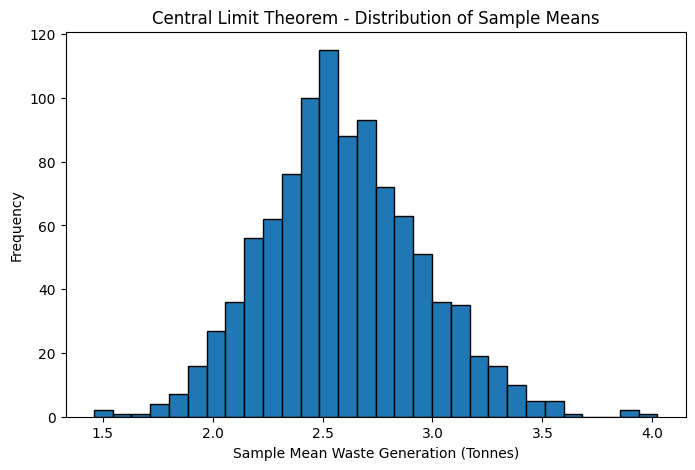

In [40]:
#Plot the distribution of sample means
plt.figure(figsize=(8, 5))

plt.hist(sample_means, bins=30, edgecolor="black")
plt.title("Central Limit Theorem - Distribution of Sample Means")
plt.xlabel("Sample Mean Waste Generation (Tonnes)")
plt.ylabel("Frequency")

plt.show()

In [41]:
#Compare population mean and sample means
print("Population Mean:", round(population_mean, 3))
print("Mean of Sample Means:", round(np.mean(sample_means), 3))
print("Standard Error:", round(np.std(sample_means, ddof=1), 3))

Population Mean: 2.604
Mean of Sample Means: 2.595
Standard Error: 0.356


# 95% Confience Interval

In [43]:
#Perform bootstrap sampling
import numpy as np

data = df["waste_generated_tonnes_perday"].dropna().values

bootstrap_means = []

for i in range(1000):
    sample = np.random.choice(data, size=len(data), replace=True)
    bootstrap_means.append(np.mean(sample))

print("Original Mean:", np.mean(data))
print("Bootstrap Mean:", np.mean(bootstrap_means))

Original Mean: 2.6042121799999998
Bootstrap Mean: 2.60391502272


In [44]:
#Calculate the 95% confidence interval
lower = np.percentile(bootstrap_means, 2.5)
upper = np.percentile(bootstrap_means, 97.5)

print("95% Confidence Interval:")
print("Lower Bound:", lower)
print("Upper Bound:", upper)

95% Confidence Interval:
Lower Bound: 2.5866734715
Upper Bound: 2.6218088975


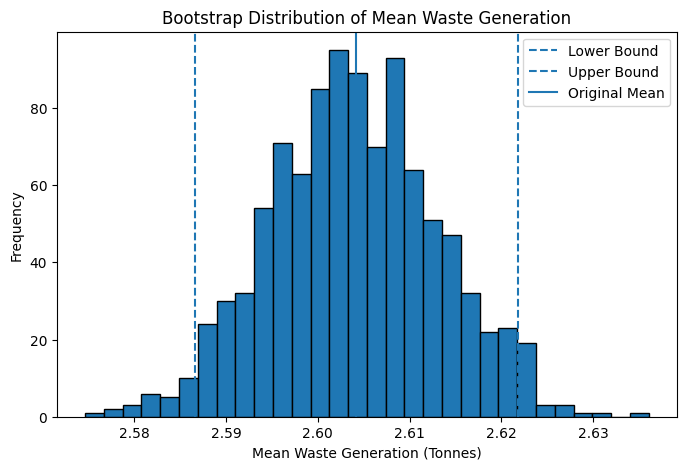

In [45]:
#Visualize bootstrap means
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(bootstrap_means, bins=30, edgecolor="black")
plt.axvline(lower, linestyle="--", label="Lower Bound")
plt.axvline(upper, linestyle="--", label="Upper Bound")
plt.axvline(np.mean(data), linestyle="-", label="Original Mean")

plt.title("Bootstrap Distribution of Mean Waste Generation")
plt.xlabel("Mean Waste Generation (Tonnes)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

# Hypothesis Testing - one sample t-test, Independent two sample t test, one way anova, chi-2 test

In [46]:
#Perform the one-sample t-test
from scipy.stats import ttest_1samp

data = df["waste_generated_tonnes_perday"].dropna()

t_stat, p_value = ttest_1samp(data, popmean=10)

print("Sample Mean:", data.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

Sample Mean: 2.6042121799999998
T-statistic: -827.100869209584
P-value: 0.0


In [47]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("The mean waste generation differs significantly from 10 tonnes.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence that the mean differs from 10 tonnes.")

Reject the null hypothesis.
The mean waste generation differs significantly from 10 tonnes.


In [48]:
#Check waste-type categories
print(df["waste_type"].value_counts(dropna=False))

waste_type
Organic    18043
Mixed       9850
Plastic     8866
Paper       5825
Glass       3426
Metal       2475
E-waste     1515
Name: count, dtype: int64


In [50]:
#Run the independent two-sample t-test
from scipy.stats import ttest_ind

organic = df.loc[
    df["waste_type"] == "Organic",
    "waste_generated_tonnes_perday"
].dropna()

plastic = df.loc[
    df["waste_type"] == "Plastic",
    "waste_generated_tonnes_perday"
].dropna()

t_stat, p_value = ttest_ind(
    organic,
    plastic,
    equal_var=False
)

print("Organic mean:", organic.mean())
print("Plastic mean:", plastic.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

Organic mean: 3.7431754142880895
Plastic mean: 1.7598926235055268
T-statistic: 103.6852934855992
P-value: 0.0


In [51]:
#Interpret the result
if p_value < 0.05:
    print("Reject H0: The mean waste generation differs significantly.")
else:
    print("Fail to reject H0: There is insufficient evidence of a difference.")

Reject H0: The mean waste generation differs significantly.


In [53]:
#Perform the ANOVA test
from scipy.stats import f_oneway

groups = [
    group["waste_generated_tonnes_perday"].dropna().values
    for name, group in df.groupby("waste_type")
]

f_stat, p_value = f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 4285.733220819616
P-value: 0.0


In [54]:
if p_value < 0.05:
    print("Reject H0: At least one waste type has a different mean.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

Reject H0: At least one waste type has a different mean.


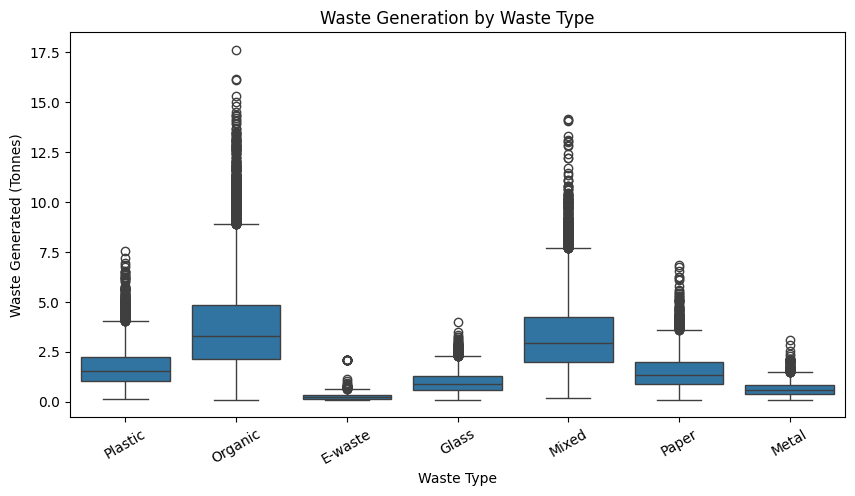

In [56]:
#Visualize the comparison
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="waste_type",
    y="waste_generated_tonnes_perday"
)

plt.title("Waste Generation by Waste Type")
plt.xlabel("Waste Type")
plt.ylabel("Waste Generated (Tonnes)")
plt.xticks(rotation=30)
plt.show()

In [57]:
#Create a contingency table
#This table counts how many records belong to each waste type in each city.
import pandas as pd

contingency_table = pd.crosstab(
    df["city"],
    df["waste_type"]
)

display(contingency_table)

waste_type,E-waste,Glass,Metal,Mixed,Organic,Paper,Plastic
city,,,,,,,
Amravati,118,253,198,742,1417,466,669
Aurangabad,137,302,211,770,1460,445,684
Kolhapur,118,262,180,769,1442,441,707
Mumbai,306,688,484,2004,3451,1146,1722
Nagpur,218,499,370,1544,2836,905,1359
Nashik,168,330,236,972,1787,585,873
Pune,204,515,386,1445,2689,837,1356
Thane,246,577,410,1604,2961,1000,1496


In [58]:
#Perform the Chi-square test
from scipy.stats import chi2_contingency

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

Chi-square statistic: 34.33446602694583
Degrees of freedom: 42
P-value: 0.7937463495714656


# Encoding and Scaling

In [60]:
#Separate features and target
X = df.drop(columns=["waste_generated_tonnes_perday", "record_id", "date"])
y = df["waste_generated_tonnes_perday"]

print("Features separated successfully!")
print(X.head())

Features separated successfully!
         city    ward waste_type  population  households  temperature_c  \
0      Nashik  NAS-51    Plastic      7859.0      1804.0           24.6   
1        Pune  PUN-58    Organic      9159.0      1953.0           26.7   
2  Aurangabad  AUR-06    E-waste     15177.0      3596.0           29.6   
3      Nashik  NAS-19      Glass     22155.0      4993.0           37.6   
4      Nagpur  NAG-44    Plastic     17785.0      3891.0           32.3   

   rainfall_mm  humidity_pct  commercial_activity_index  tourism_index  \
0          2.2          41.5                       97.0           82.0   
1          1.6          55.7                       99.0           50.0   
2          0.0          44.0                       53.0           82.0   
3         25.9          79.6                       54.0           44.0   
4          1.7          53.6                       15.0           49.0   

   festival_flag day_of_week  weekend_flag  
0            1.0     Tuesd

In [61]:
#Identify numerical and categorical columns
import numpy as np

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical columns:", numeric_features)
print("Categorical columns:", categorical_features)

Numerical columns: ['population', 'households', 'temperature_c', 'rainfall_mm', 'humidity_pct', 'commercial_activity_index', 'tourism_index', 'festival_flag', 'weekend_flag']
Categorical columns: ['city', 'ward', 'waste_type', 'day_of_week']


In [62]:
#Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (40000, 13)
Testing data: (10000, 13)


In [63]:
#Apply StandardScaler
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train[numeric_features])
X_test_num = scaler.transform(X_test[numeric_features])

print("Standard Scaling completed!")

Standard Scaling completed!


In [64]:
#Apply OneHotEncoder
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

X_train_cat = encoder.fit_transform(X_train[categorical_features])
X_test_cat = encoder.transform(X_test[categorical_features])

print("One-Hot Encoding completed!")
print("Encoded training shape:", X_train_cat.shape)

One-Hot Encoding completed!
Encoded training shape: (40000, 502)


In [65]:
#Combine the processed features
import numpy as np

X_train_processed = np.concatenate(
    [X_train_num, X_train_cat], axis=1
)

X_test_processed = np.concatenate(
    [X_test_num, X_test_cat], axis=1
)

print("Final training shape:", X_train_processed.shape)
print("Final testing shape:", X_test_processed.shape)

Final training shape: (40000, 511)
Final testing shape: (10000, 511)


# Regression Models

In [66]:
#Apply Multiple Regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

model = LinearRegression()
model.fit(X_train_processed, y_train)

y_pred = model.predict(X_test_processed)

print("R² Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R² Score: 0.7716295099248446
MAE: 0.6738600819377311
RMSE: 0.9469045776943571


In [67]:
#decision tree
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train_processed, y_train)

y_pred_dt = dt_model.predict(X_test_processed)

print("Decision Tree Regression Results")
print("R² Score:", r2_score(y_test, y_pred_dt))
print("MAE:", mean_absolute_error(y_test, y_pred_dt))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_dt)))

Decision Tree Regression Results
R² Score: 0.7620594736862517
MAE: 0.6035241
RMSE: 0.9665413380192283


In [68]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Ridge Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_processed, y_train)

y_pred_ridge = ridge_model.predict(X_test_processed)

print("RIDGE REGRESSION")
print("R2 Score:", r2_score(y_test, y_pred_ridge))
print("MAE:", mean_absolute_error(y_test, y_pred_ridge))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ridge)))

RIDGE REGRESSION
R2 Score: 0.7717166063638718
MAE: 0.6735721697184223
RMSE: 0.946723994201218


In [69]:
# Lasso Regression
lasso_model = Lasso(alpha=0.01, max_iter=10000)
lasso_model.fit(X_train_processed, y_train)

y_pred_lasso = lasso_model.predict(X_test_processed)

print("\nLASSO REGRESSION")
print("R2 Score:", r2_score(y_test, y_pred_lasso))
print("MAE:", mean_absolute_error(y_test, y_pred_lasso))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lasso)))


LASSO REGRESSION
R2 Score: 0.7717849054458172
MAE: 0.6637277059304323
RMSE: 0.9465823605595516


In [70]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

y_pred_rf = rf_model.predict(X_test_processed)

print("Random Forest Regression Results")
print("R² Score:", r2_score(y_test, y_pred_rf))
print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))

Random Forest Regression Results
R² Score: 0.8749419672428017
MAE: 0.429919226
RMSE: 0.7007159778999192


Step 15: Create the final comparison table

In [71]:
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

models = {
    "Linear Regression": y_pred,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Ridge Regression": y_pred_ridge,
    "Lasso Regression": y_pred_lasso
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="R2 Score", ascending=False)

print(results_df.round(4).to_string(index=False))

            Model  R2 Score    MAE   RMSE
    Random Forest    0.8749 0.4299 0.7007
 Lasso Regression    0.7718 0.6637 0.9466
 Ridge Regression    0.7717 0.6736 0.9467
Linear Regression    0.7716 0.6739 0.9469
    Decision Tree    0.7621 0.6035 0.9665


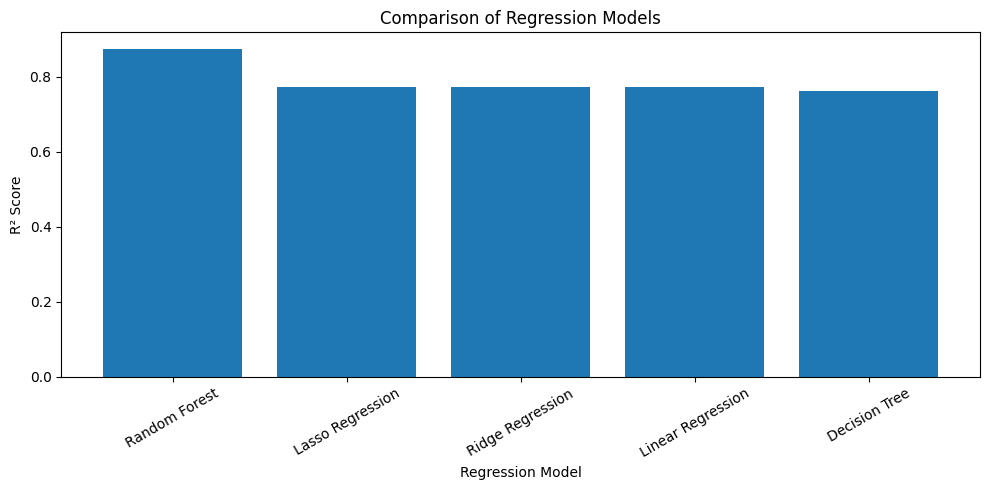

In [72]:
#Visualize model performance
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.title("Comparison of Regression Models")
plt.xlabel("Regression Model")
plt.ylabel("R² Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Best Model

In [73]:
#Identify the best model
best_model_name = results_df.iloc[0]["Model"]

print("Best model based on R²:", best_model_name)
print("Highest R² Score:", round(results_df.iloc[0]["R2 Score"], 4))
print("MAE:", round(results_df.iloc[0]["MAE"], 4))
print("RMSE:", round(results_df.iloc[0]["RMSE"], 4))

Best model based on R²: Random Forest
Highest R² Score: 0.8749
MAE: 0.4299
RMSE: 0.7007


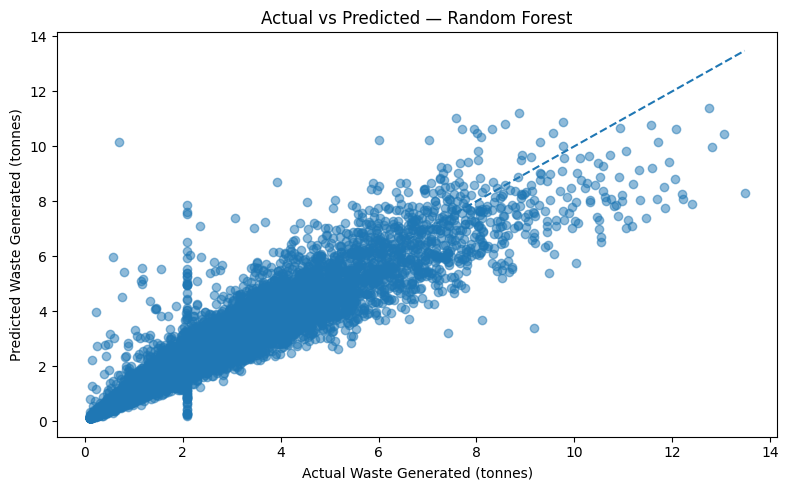

In [74]:
#Plot actual vs predicted waste generation
import matplotlib.pyplot as plt

best_model_name = results_df.iloc[0]["Model"]
best_predictions = models[best_model_name]

plt.figure(figsize=(8, 5))
plt.scatter(y_test, best_predictions, alpha=0.5)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Waste Generated (tonnes)")
plt.ylabel("Predicted Waste Generated (tonnes)")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.tight_layout()
plt.show()

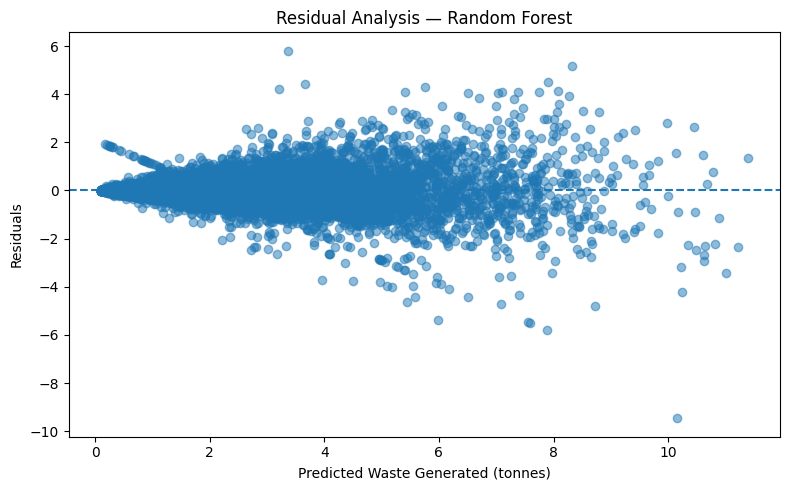

In [75]:
#Residual analysis
residuals = y_test - best_predictions

plt.figure(figsize=(8, 5))
plt.scatter(best_predictions, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Waste Generated (tonnes)")
plt.ylabel("Residuals")
plt.title(f"Residual Analysis — {best_model_name}")
plt.tight_layout()
plt.show()

In [76]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

print("Selected Model:", best_model_name)
print("R² Score:", round(r2_score(y_test, best_predictions), 4))
print("MAE:", round(mean_absolute_error(y_test, best_predictions), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, best_predictions)), 4))

Selected Model: Random Forest
R² Score: 0.8749
MAE: 0.4299
RMSE: 0.7007


In [77]:
best_model_name = results_df.iloc[0]["Model"]

model_objects = {
    "Linear Regression": model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model
}

best_model = model_objects[best_model_name]

In [78]:
import joblib
joblib.dump(best_model, "best_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(encoder, "encoder.pkl")

['encoder.pkl']

In [79]:
print("Saved model:", best_model_name)

Saved model: Random Forest


In [80]:
joblib.dump(numeric_features, "numeric_features.pkl")
joblib.dump(categorical_features, "categorical_features.pkl")

['categorical_features.pkl']